# Coefficient of Performance (COP) of the Ideal Vapor-Compression Refrigeration Cycle (冷凍サイクルの成績係数)

The **ideal vapor-compression cycle** is the standard model for refrigerators, air conditioners and heat pumps. It has 4 processes:

| State | Process | Description |
|---|---|---|
| 1 → 2 | Isentropic compression | Compressor raises saturated vapor from evaporator pressure $p_e$ to condenser pressure $p_c$ |
| 2 → 3 | Constant-pressure heat rejection | Condenser cools superheated vapor to saturated liquid at $p_c$ |
| 3 → 4 | Throttling (isenthalpic) | Expansion valve drops pressure back to $p_e$, $h_4=h_3$ |
| 4 → 1 | Constant-pressure heat absorption | Evaporator boils the two-phase refrigerant to saturated vapor at $p_e$ |

$$COP_R = \frac{q_L}{w_{in}} = \frac{h_1-h_4}{h_2-h_1}$$

Refrigerant R-134a properties come from [PYroMat](https://pyromat.org/) (`mp.C2H2F4`).

Reference: [Wikipedia - Vapor-compression refrigeration](https://en.wikipedia.org/wiki/Vapor-compression_refrigeration)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyromat as pm

pm.config['unit_pressure'] = 'MPa'   # SI-derived pressure unit throughout (PYroMat defaults to bar)
r134a = pm.get('mp.C2H2F4')          # R-134a; remaining PYroMat unit defaults: K, kJ/kg, kJ/kg-K

class RefrigerationCycle:
    # Ideal (no losses) vapor-compression refrigeration cycle.

    def __init__(self, T_evap, p_cond):
        # INPUT INITIAL INFORMATION
        #   T_evap : evaporator (compressor inlet) saturation temperature [K]
        #   p_cond : condenser pressure [MPa]
        self.Te = T_evap
        self.pc = p_cond
        self._solve()

    def _solve(self):
        self.pe = r134a.ps(T=self.Te).item()      # evaporator (low) pressure

        # state 1 : compressor inlet, saturated vapor at Te
        hf_e, hg_e = r134a.hs(T=self.Te)
        sf_e, sg_e = r134a.ss(T=self.Te)
        self.h1, self.s1 = hg_e[0], sg_e[0]

        # state 2 : compressor exit (isentropic compression to condenser pressure)
        T2, x2 = r134a.T_s(s=self.s1, p=self.pc, quality=True)
        self.T2 = T2[0]
        self.h2 = r134a.h(T=self.T2, p=self.pc).item()

        # state 3 : condenser exit, saturated liquid at pc
        hf_c, hg_c = r134a.hs(p=self.pc)
        self.h3 = hf_c[0]

        # state 4 : expansion valve exit (isenthalpic throttling)
        self.h4 = self.h3

        # energy balance
        self.q_L = self.h1-self.h4     # refrigeration effect
        self.q_H = self.h2-self.h3     # heat rejected at condenser
        self.w_in = self.h2-self.h1    # compressor work
        self.COP_R = self.q_L/self.w_in            # refrigerator
        self.COP_HP = self.q_H/self.w_in            # heat pump

    def summary(self):
        print(f"Evaporator pressure  pe = {self.pe:.4f} MPa  (Te = {self.Te-273.15:.1f} degC)")
        print(f"Condenser pressure   pc = {self.pc:.4f} MPa")
        print()
        print(f"State 1 (compr. in)  : h1={self.h1:8.2f} kJ/kg, s1={self.s1:.4f} kJ/kg-K")
        print(f"State 2 (compr. out) : h2={self.h2:8.2f} kJ/kg  (T2={self.T2-273.15:.1f} degC)")
        print(f"State 3 (cond. out)  : h3={self.h3:8.2f} kJ/kg")
        print(f"State 4 (valve out)  : h4={self.h4:8.2f} kJ/kg")
        print()
        print(f"q_L (refrigeration effect) = {self.q_L:.2f} kJ/kg")
        print(f"q_H (heat rejected)         = {self.q_H:.2f} kJ/kg")
        print(f"w_in (compressor work)      = {self.w_in:.2f} kJ/kg")
        print(f"COP_R  (refrigerator)       = {self.COP_R:.3f}")
        print(f"COP_HP (heat pump)          = {self.COP_HP:.3f}")

### Sample: R-134a, evaporator at -20°C, condenser at 0.8 MPa
A standard worked example (Cengel & Boles): evaporator saturation temperature -20°C, condenser pressure 0.8 MPa. Note $COP_{HP} = COP_R + 1$ always holds (same $w_{in}$, and $q_H = q_L + w_{in}$ by energy balance).

In [2]:
cycle = RefrigerationCycle(T_evap=-20+273.15, p_cond=0.8)
cycle.summary()
print(f"\nCheck COP_HP - COP_R = {cycle.COP_HP-cycle.COP_R:.4f} (should be 1.0000)")

Evaporator pressure  pe = 0.1327 MPa  (Te = -20.0 degC)
Condenser pressure   pc = 0.8000 MPa

State 1 (compr. in)  : h1=  386.55 kJ/kg, s1=1.7413 kJ/kg-K
State 2 (compr. out) : h2=  423.87 kJ/kg  (T2=39.3 degC)
State 3 (cond. out)  : h3=  243.65 kJ/kg
State 4 (valve out)  : h4=  243.65 kJ/kg

q_L (refrigeration effect) = 142.90 kJ/kg
q_H (heat rejected)         = 180.22 kJ/kg
w_in (compressor work)      = 37.31 kJ/kg
COP_R  (refrigerator)       = 3.830
COP_HP (heat pump)          = 4.830

Check COP_HP - COP_R = 1.0000 (should be 1.0000)


In [3]:
from rich.console import Console
from rich.table import Table

console = Console()

states = Table(title="Refrigeration cycle state points")
states.add_column("State"); states.add_column("h [kJ/kg]", justify="right"); states.add_column("Note")
states.add_row("1 (compressor in)",  f"{cycle.h1:.2f}", "sat. vapor @ Te")
states.add_row("2 (compressor out)", f"{cycle.h2:.2f}", f"T2 = {cycle.T2-273.15:.1f} degC")
states.add_row("3 (condenser out)",  f"{cycle.h3:.2f}", "sat. liquid @ pc")
states.add_row("4 (valve out)",      f"{cycle.h4:.2f}", "h4 = h3 (throttling)")
console.print(states)

results = Table(title="Cycle performance")
results.add_column("Quantity"); results.add_column("Value", justify="right")
results.add_row("q_L (refrigeration effect)", f"{cycle.q_L:.2f} kJ/kg")
results.add_row("q_H (heat rejected)",         f"{cycle.q_H:.2f} kJ/kg")
results.add_row("w_in (compressor work)",      f"{cycle.w_in:.2f} kJ/kg")
results.add_row("COP_R (refrigerator)",  f"{cycle.COP_R:.3f}", style="bold green")
results.add_row("COP_HP (heat pump)",    f"{cycle.COP_HP:.3f}", style="bold cyan")
console.print(results)

           Refrigeration cycle state points           
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ State              ┃      h ┃ Note                 ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ 1 (compressor in)  │ 386.55 │ sat. vapor @ Te      │
│ 2 (compressor out) │ 423.87 │ T2 = 39.3 degC       │
│ 3 (condenser out)  │ 243.65 │ sat. liquid @ pc     │
│ 4 (valve out)      │ 243.65 │ h4 = h3 (throttling) │
└────────────────────┴────────┴──────────────────────┘

              Cycle performance              
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Quantity                   ┃        Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ q_L (refrigeration effect) │ 142.90 kJ/kg │
│ q_H (heat rejected)        │ 180.22 kJ/kg │
│ w_in (compressor work)     │  37.31 kJ/kg │
│ COP_R (refrigerator)       │        3.830 │
│ COP_HP (heat pump)         │        4.830 │
└────────────────────────────┴──────────────┘

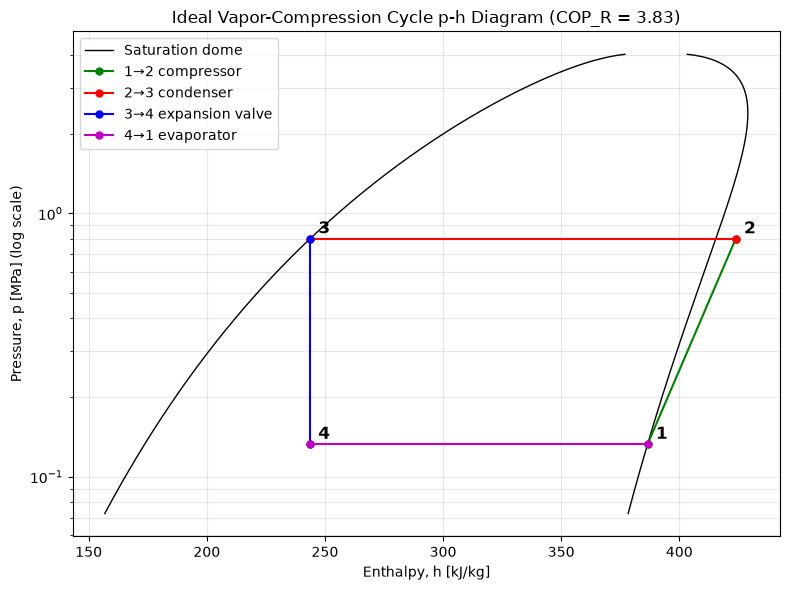

In [4]:
# p-h diagram (common refrigeration-cycle chart) with saturation dome
T_dome = np.linspace(240, r134a.critical()[0]-0.5, 300)
hf_dome, hg_dome = r134a.hs(T=T_dome)
p_dome = r134a.ps(T=T_dome)

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(hf_dome, p_dome, 'k-', lw=1)
ax.plot(hg_dome, p_dome, 'k-', lw=1, label='Saturation dome')

h12 = np.linspace(cycle.h1, cycle.h2, 2)
ax.plot([cycle.h1, cycle.h2], [cycle.pe, cycle.pc], 'g-o', ms=5, label='1→2 compressor')
ax.plot([cycle.h2, cycle.h3], [cycle.pc, cycle.pc], 'r-o', ms=5, label='2→3 condenser')
ax.plot([cycle.h3, cycle.h4], [cycle.pc, cycle.pe], 'b-o', ms=5, label='3→4 expansion valve')
ax.plot([cycle.h4, cycle.h1], [cycle.pe, cycle.pe], 'm-o', ms=5, label='4→1 evaporator')

for lbl, h, p in [('1',cycle.h1,cycle.pe), ('2',cycle.h2,cycle.pc),
                   ('3',cycle.h3,cycle.pc), ('4',cycle.h4,cycle.pe)]:
    ax.annotate(lbl, (h,p), textcoords="offset points", xytext=(6,4), fontsize=12, fontweight='bold')

ax.set_yscale('log')
ax.set_xlabel('Enthalpy, h [kJ/kg]')
ax.set_ylabel('Pressure, p [MPa] (log scale)')
ax.set_title(f'Ideal Vapor-Compression Cycle p-h Diagram (COP_R = {cycle.COP_R:.2f})')
ax.legend()
ax.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

### Effect of evaporator temperature on COP
Lowering the evaporator temperature (e.g. asking a freezer to run colder) reduces COP - the compressor must work across a bigger pressure/temperature lift for the same heat rejection condition.

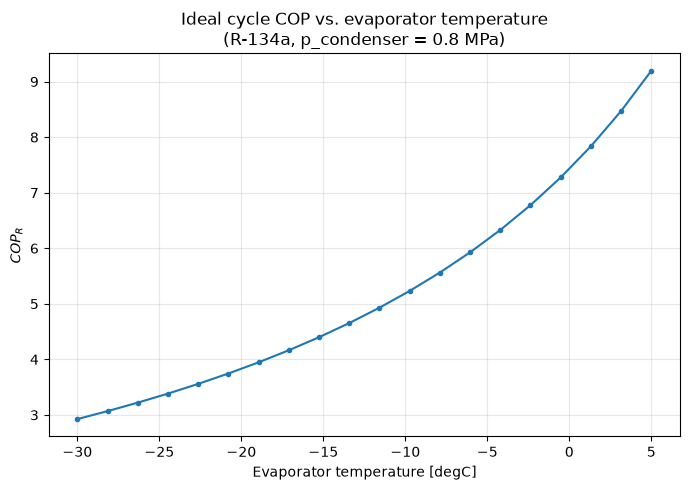

In [5]:
Te_range = np.linspace(-30, 5, 20)+273.15
cops = [RefrigerationCycle(T_evap=Te, p_cond=0.8).COP_R for Te in Te_range]

plt.figure(figsize=(7,5))
plt.plot(Te_range-273.15, cops, marker='.')
plt.xlabel('Evaporator temperature [degC]')
plt.ylabel(r'$COP_R$')
plt.title('Ideal cycle COP vs. evaporator temperature\n(R-134a, p_condenser = 0.8 MPa)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reference :
1. [Wikipedia - Vapor-compression refrigeration](https://en.wikipedia.org/wiki/Vapor-compression_refrigeration)
2. [PYroMat documentation](https://pyromat.org/)